In [1]:
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict
load_dotenv()
model=ChatOpenAI()

python-dotenv could not parse statement starting at line 5


In [2]:
#define the state
class LLMqaState(TypedDict):
    question:str
    answer:str

In [3]:
def LLmqa(state:LLMqaState)->LLMqaState:
    question=state['question']
    prompt=f'answer the following question:{question}'
    answer=model.invoke(prompt).content
    state['answer']=answer
    return state

In [4]:
#define node
graph=StateGraph(LLMqaState)
#create nodes
graph.add_node('LLMqa',LLmqa)

#create edges
graph.add_edge(START,'LLMqa')
graph.add_edge('LLMqa',END)

#compile the workflow
workflow=graph.compile()

initial_state={'question':"how far we can go beyond our galaxy"}

final_state=workflow.invoke(initial_state)

print(final_state)

print(final_state['answer']) # to see only the answer

{'question': 'how far we can go beyond our galaxy', 'answer': 'As of current technological capabilities, it is impossible for humans to travel beyond our own galaxy, the Milky Way. The Milky Way is approximately 100,000 light-years in diameter, and even traveling at the speed of light, it would take thousands of years to reach another galaxy. Additionally, the vast distances and unknown hazards of intergalactic space make it unlikely that humans will be able to travel beyond our galaxy in the foreseeable future. However, advancements in technology and theoretical concepts such as warp drive or wormholes may one day make intergalactic travel a possibility.'}
As of current technological capabilities, it is impossible for humans to travel beyond our own galaxy, the Milky Way. The Milky Way is approximately 100,000 light-years in diameter, and even traveling at the speed of light, it would take thousands of years to reach another galaxy. Additionally, the vast distances and unknown hazards

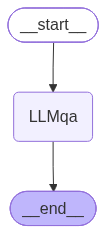

In [5]:
graph.compile()